<a href="https://colab.research.google.com/github/Rukshana-S/parking-utilization-insight/blob/main/Parking_Utilization_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:

# ROUND 2 - STEP 1: LOAD AND UNDERSTAND DATA

from google.colab import drive
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Mount Google Drive if needed
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")
else:
    print("Google Drive already mounted.")

sns.set_theme(style="whitegrid")

# Automatically locate the folder containing all CSV files
BASE_PATH = "/content/drive/MyDrive/Parking_Utilization_Data"

required_files = [
    "parking_sessions.csv",
    "zones.csv",
    "payments.csv",
    "calendar.csv",
    "weather.csv"
]

DATA_PATH = None

for root, dirs, files in os.walk(BASE_PATH):
    if all(file in files for file in required_files):
        DATA_PATH = root
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find all five CSV files in Google Drive."
    )

print("Dataset folder:", DATA_PATH)

# Load datasets
parking_raw = pd.read_csv(os.path.join(DATA_PATH, "parking_sessions.csv"))
zones_raw = pd.read_csv(os.path.join(DATA_PATH, "zones.csv"))
payments_raw = pd.read_csv(os.path.join(DATA_PATH, "payments.csv"))
calendar_raw = pd.read_csv(os.path.join(DATA_PATH, "calendar.csv"))
weather_raw = pd.read_csv(os.path.join(DATA_PATH, "weather.csv"))

datasets = {
    "Parking Sessions": parking_raw,
    "Zones": zones_raw,
    "Payments": payments_raw,
    "Calendar": calendar_raw,
    "Weather": weather_raw
}

# Display dataset dimensions and sample records
print("\n========== DATASET OVERVIEW ==========")

for name, df in datasets.items():
    print(f"\n{name}: {df.shape[0]} records, {df.shape[1]} attributes")
    display(df.head(3))

# Check data quality
print("\n========== DATA QUALITY CHECK ==========")

for name, df in datasets.items():
    print(f"\n{name}")
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Columns:", df.columns.tolist())

print("\nSTEP 1 COMPLETED")


Google Drive already mounted.
Dataset folder: /content/drive/MyDrive/Parking_Utilization_Data/parking_utilization

========== DATASET OVERVIEW ==========

Parking Sessions: 500 records, 6 attributes


,session_id,zone,entry,exit,duration,fee
0,S00001,ZONE E,2025-01-01 13:20:00,2025-01-01 17:11:00,3.85,49.80
1,S00002,Zone B,2025-01-02 07:24:00,2025-01-02 08:01:00,0.62,10.00
2,S00003,Zone C,2025-01-03 17:37:00,2025-01-03 19:20:00,1.72,30.76



Zones: 500 records, 5 attributes


,zone_id,zone,location,capacity,zone_type
0,Z001,Zone A,City Centre,80,Commercial
1,Z002,Zone B,Market Street,60,Commercial
2,Z003,Zone C,Railway Station,100,Transit



Payments: 500 records, 4 attributes


...


Calendar: 500 records, 4 attributes


,date,weekday,holiday,event
0,2025-01-01,Wednesday,0,0
1,2025-01-02,Thursday,0,0
2,2025-01-03,Friday,0,0



Weather: 500 records, 3 attributes


,date,rain,temperature
0,2025-01-01,0,26.2
1,2025-01-02,0,30.9
2,2025-01-03,0,30.0



========== DATA QUALITY CHECK ==========

Parking Sessions
Missing values: 22
Duplicate rows: 0
Columns: ['session_id', 'zone', 'entry', 'exit', 'duration', 'fee']

Zones
Missing values: 0
Duplicate rows: 0
Columns: ['zone_id', 'zone', 'location', 'capacity', 'zone_type']

Payments
Missing values: 5
Duplicate rows: 0
Columns: ['payment_id', 'session_id', 'payment_mode', 'amount']

Calendar
Missing values: 0
Duplicate rows: 0
Columns: ['date', 'weekday', 'holiday', 'event']

Weather
Missing values: 0
Duplicate rows: 0
Columns: ['date', 'rain', 'temperature']

STEP 1 COMPLETED


In [7]:

# ============================================================
# ROUND 2 - STEP 2: DATA CLEANING AND PREPROCESSING
# ============================================================

# Work on copies of the original datasets
parking = parking_raw.copy()
zones = zones_raw.copy()
payments = payments_raw.copy()
calendar = calendar_raw.copy()
weather = weather_raw.copy()

# 1. Standardize column names
for df in [parking, zones, payments, calendar, weather]:
    df.columns = df.columns.str.strip().str.lower()

# 2. Standardize zone names
def normalize_zone(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"[-_]+", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

parking["zone"] = normalize_zone(parking["zone"])
zones["zone"] = normalize_zone(zones["zone"])

# 3. Convert columns to correct data types
parking["entry"] = pd.to_datetime(parking["entry"], errors="coerce")
parking["exit"] = pd.to_datetime(parking["exit"], errors="coerce")
parking["duration"] = pd.to_numeric(parking["duration"], errors="coerce")
parking["fee"] = pd.to_numeric(parking["fee"], errors="coerce")

zones["capacity"] = pd.to_numeric(zones["capacity"], errors="coerce")
payments["amount"] = pd.to_numeric(payments["amount"], errors="coerce")

calendar["date"] = pd.to_datetime(calendar["date"], errors="coerce")
weather["date"] = pd.to_datetime(weather["date"], errors="coerce")

# 4. Remove duplicate parking records
before = len(parking)

parking = parking.drop_duplicates(subset=["session_id"], keep="first")
parking = parking.drop_duplicates(
    subset=["zone", "entry", "exit", "duration", "fee"],
    keep="first"
).copy()

print("Duplicate parking records removed:", before - len(parking))

# 5. Recalculate duration using valid timestamps
calculated_duration = (
    (parking["exit"] - parking["entry"]).dt.total_seconds() / 3600
)

valid_duration = calculated_duration.ge(0)
parking.loc[valid_duration, "duration"] = calculated_duration[valid_duration]

# Negative durations are invalid
parking.loc[parking["duration"] < 0, "duration"] = np.nan

# Remove records without a valid entry timestamp
parking = parking.dropna(subset=["entry"]).copy()

# Flag missing exits and do not invent their durations
parking["exit_missing"] = parking["exit"].isna()
parking.loc[parking["exit_missing"], "duration"] = np.nan

# Negative fees are invalid
parking.loc[parking["fee"] < 0, "fee"] = np.nan

# 6. Clean lookup tables
calendar = calendar.dropna(subset=["date"]).drop_duplicates(subset=["date"])
weather = weather.dropna(subset=["date"]).drop_duplicates(subset=["date"])

# 7. Fix repeated zone names before merging
# Retain one representative record for each canonical zone.
zones_unique = (
    zones[["zone", "location", "capacity", "zone_type"]]
    .dropna(subset=["zone"])
    .drop_duplicates(subset=["zone"], keep="first")
)

# 8. Report cleaned results
print("\n========== CLEANING SUMMARY ==========")
print("Original parking rows:", len(parking_raw))
print("Cleaned parking rows:", len(parking))
print("Unique zone names:", zones_unique["zone"].nunique())

print("\nMissing values in cleaned parking data:")
print(parking.isnull().sum())

print("\nCanonical zone information:")
display(zones_unique)

print("\nSample of cleaned parking data:")
display(parking.head())

print("\nSTEP 2 COMPLETED SUCCESSFULLY!")


Duplicate parking records removed: 8

========== CLEANING SUMMARY ==========
Original parking rows: 500
Cleaned parking rows: 492
Unique zone names: 5

Missing values in cleaned parking data:
session_id       0
zone             0
entry            0
exit            10
duration        10
fee              0
exit_missing     0
dtype: int64

Canonical zone information:


,zone,location,capacity,zone_type
0,Zone A,City Centre,80,Commercial
1,Zone B,Market Street,60,Commercial
2,Zone C,Railway Station,100,Transit
3,Zone D,Hospital Road,50,Hospital
4,Zone E,Park Avenue,70,Recreational



Sample of cleaned parking data:


,session_id,zone,entry,exit,duration,fee,exit_missing
0,S00001,Zone E,2025-01-01 13:20:00,2025-01-01 17:11:00,3.850000,49.80,False
1,S00002,Zone B,2025-01-02 07:24:00,2025-01-02 08:01:00,0.616667,10.00,False
2,S00003,Zone C,2025-01-03 17:37:00,2025-01-03 19:20:00,1.716667,30.76,False
3,S00004,Zone D,2025-01-04 20:07:00,2025-01-04 21:08:00,1.016667,28.31,False
4,S00005,Zone B,2025-01-05 20:00:00,2025-01-05 21:33:00,1.550000,21.41,False



STEP 2 COMPLETED SUCCESSFULLY!


In [8]:

# ============================================================
# ROUND 2 - STEP 2B: CLEAN PAYMENTS, ZONES, CALENDAR & WEATHER
# ============================================================

# 1. CLEAN PAYMENTS
print("Payments missing values before cleaning:")
print(payments.isnull().sum())

# Check whether missing amounts can be recovered from parking fees
payment_lookup = parking[["session_id", "fee"]].drop_duplicates(
    subset=["session_id"]
).set_index("session_id")["fee"]

missing_amount = payments["amount"].isna()
payments.loc[missing_amount, "amount"] = (
    payments.loc[missing_amount, "session_id"].map(payment_lookup)
)

# If no valid corresponding fee exists, retain NaN rather than guessing
payments["amount"] = payments["amount"].where(
    payments["amount"] >= 0, np.nan
)

# Standardize payment mode labels
payments["payment_mode"] = (
    payments["payment_mode"].astype("string").str.strip().str.upper()
)

print("\nPayments missing values after cleaning:")
print(payments.isnull().sum())

# 2. CLEAN ZONE DATA
zones["capacity"] = pd.to_numeric(zones["capacity"], errors="coerce")

# Invalid capacities are marked missing
zones.loc[zones["capacity"] <= 0, "capacity"] = np.nan

print("\nZones missing values:")
print(zones.isnull().sum())

# 3. CLEAN CALENDAR DATA
calendar["weekday"] = (
    calendar["date"].dt.day_name()
)

for col in ["holiday", "event"]:
    calendar[col] = pd.to_numeric(calendar[col], errors="coerce")

print("\nCalendar missing values:")
print(calendar.isnull().sum())

# 4. CLEAN WEATHER DATA
weather["rain"] = pd.to_numeric(weather["rain"], errors="coerce")
weather["temperature"] = pd.to_numeric(
    weather["temperature"], errors="coerce"
)

# Keep only valid binary rain values
weather.loc[~weather["rain"].isin([0, 1]), "rain"] = np.nan

print("\nWeather missing values:")
print(weather.isnull().sum())

# 5. FINAL DATA QUALITY REPORT
cleaned_datasets = {
    "Parking": parking,
    "Zones": zones,
    "Payments": payments,
    "Calendar": calendar,
    "Weather": weather
}

print("\n========== FINAL DATA QUALITY REPORT ==========")

for name, df in cleaned_datasets.items():
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Missing values:", df.isnull().sum().to_dict())
    print("Duplicate rows:", df.duplicated().sum())

print("\nSTEP 2B COMPLETED!")


Payments missing values before cleaning:
payment_id      0
session_id      0
payment_mode    0
amount          5
dtype: int64

Payments missing values after cleaning:
payment_id      0
session_id      0
payment_mode    0
amount          0
dtype: int64

Zones missing values:
zone_id      0
zone         0
location     0
capacity     0
zone_type    0
dtype: int64

Calendar missing values:
date       0
weekday    0
holiday    0
event      0
dtype: int64

Weather missing values:
date           0
rain           0
temperature    0
dtype: int64

========== FINAL DATA QUALITY REPORT ==========

Parking
Rows: 492
Missing values: {'session_id': 0, 'zone': 0, 'entry': 0, 'exit': 10, 'duration': 10, 'fee': 0, 'exit_missing': 0}
Duplicate rows: 0

Zones
Rows: 500
Missing values: {'zone_id': 0, 'zone': 0, 'location': 0, 'capacity': 0, 'zone_type': 0}
Duplicate rows: 0

Payments
Rows: 500
Missing values: {'payment_id': 0, 'session_id': 0, 'payment_mode': 0, 'amount': 0}
Duplicate rows: 0

Calendar
Row

In [9]:

# ============================================================
# ROUND 2 - STEP 3: DATA INTEGRATION & FEATURE ENGINEERING
# ============================================================

# 1. CREATE ANALYSIS DATE
parking["date"] = parking["entry"].dt.normalize()

# 2. CREATE TIME-BASED FEATURES
parking["entry_hour"] = parking["entry"].dt.hour
parking["day_of_week"] = parking["entry"].dt.day_name()

parking["is_weekend"] = (
    parking["entry"].dt.dayofweek >= 5
).astype(int)

parking["time_period"] = pd.cut(
    parking["entry_hour"],
    bins=[-1, 5, 11, 16, 20, 23],
    labels=["Night", "Morning", "Afternoon", "Evening", "Late Night"]
)

parking["parking_duration"] = parking["duration"]

# 3. PREPARE UNIQUE ZONE LOOKUP
zones_unique = (
    zones[["zone", "location", "capacity", "zone_type"]]
    .dropna(subset=["zone"])
    .drop_duplicates(subset=["zone"], keep="first")
)

assert zones_unique["zone"].is_unique, "Zone names must be unique!"

# 4. PREPARE CALENDAR AND WEATHER LOOKUPS
calendar_lookup = calendar[
    ["date", "holiday", "event"]
].drop_duplicates(subset=["date"])

weather_lookup = weather[
    ["date", "rain", "temperature"]
].drop_duplicates(subset=["date"])

# 5. MERGE PARKING WITH ZONE DETAILS
data = parking.merge(
    zones_unique,
    on="zone",
    how="left",
    validate="many_to_one"
)

# 6. MERGE CALENDAR INFORMATION
data = data.merge(
    calendar_lookup,
    on="date",
    how="left",
    validate="many_to_one"
)

# 7. MERGE WEATHER INFORMATION
data = data.merge(
    weather_lookup,
    on="date",
    how="left",
    validate="many_to_one"
)

# 8. PREPARE AND MERGE PAYMENT DETAILS
payment_summary = payments.groupby(
    "session_id", as_index=False
).agg(
    payment_amount=("amount", "sum"),
    payment_mode=("payment_mode", "first")
)

data = data.merge(
    payment_summary,
    on="session_id",
    how="left",
    validate="many_to_one"
)

# 9. CREATE EVENT AND WEATHER FEATURES
data["is_event_day"] = data["event"].map(
    {0: 0, 1: 1}
).astype("Int64")

data["is_rainy"] = data["rain"].map(
    {0: "No Rain", 1: "Rain"}
)

# 10. VALIDATE THE MERGED DATA
print("========== DATA INTEGRATION RESULTS ==========")
print("Cleaned parking records:", len(parking))
print("Merged records:", len(data))
print("Merged columns:", len(data.columns))
print("Duplicate session IDs:", data["session_id"].duplicated().sum())
print("Unmatched zones:", data["capacity"].isna().sum())

print("\n========== ENGINEERED FEATURES ==========")
feature_columns = [
    "session_id", "zone", "entry_hour", "day_of_week",
    "is_weekend", "time_period", "parking_duration",
    "capacity", "zone_type", "event", "rain", "temperature"
]

display(data[feature_columns].head(10))

print("\n========== FEATURE SUMMARY ==========")
display(
    data[[
        "entry_hour", "is_weekend", "parking_duration",
        "capacity", "temperature"
    ]].describe()
)

print("\nSTEP 3 COMPLETED SUCCESSFULLY!")


========== DATA INTEGRATION RESULTS ==========
Cleaned parking records: 492
Merged records: 492
Merged columns: 24
Duplicate session IDs: 0
Unmatched zones: 0

========== ENGINEERED FEATURES ==========


,session_id,zone,entry_hour,day_of_week,is_weekend,time_period,parking_duration,capacity,zone_type,event,rain,temperature
0,S00001,Zone E,13,Wednesday,0,Afternoon,3.850000,70.0,Recreational,0,0.0,26.2
1,S00002,Zone B,7,Thursday,0,Morning,0.616667,60.0,Commercial,0,0.0,30.9
2,S00003,Zone C,17,Friday,0,Evening,1.716667,100.0,Transit,0,0.0,30.0
3,S00004,Zone D,20,Saturday,1,Evening,1.016667,50.0,Hospital,0,0.0,26.7
4,S00005,Zone B,20,Sunday,1,Evening,1.550000,60.0,Commercial,1,0.0,28.0
5,S00006,Zone B,12,Monday,0,Afternoon,2.750000,60.0,Commercial,0,0.0,28.8
6,S00007,Zone E,10,Tuesday,0,Morning,3.733333,70.0,Recreational,0,0.0,31.5
7,S00008,Zone C,6,Wednesday,0,Morning,3.633333,100.0,Transit,0,0.0,34.0
8,S00009,Zone D,12,Thursday,0,Afternoon,NaN,50.0,Hospital,0,1.0,30.7
9,S00010,Zone A,14,Friday,0,Afternoon,0.283333,80.0,Commercial,0,1.0,27.4



========== FEATURE SUMMARY ==========


,entry_hour,is_weekend,parking_duration,capacity,temperature
count,492.000000,492.000000,482.000000,492.000000,492.000000
mean,14.428862,0.286585,2.189004,71.382114,29.967886
std,4.876585,0.452626,1.485057,16.937657,3.371732
min,6.000000,0.000000,0.250000,50.000000,20.400000
25%,10.000000,0.000000,1.050000,60.000000,27.700000
50%,14.000000,0.000000,1.900000,70.000000,29.950000
75%,19.000000,1.000000,3.029167,80.000000,32.300000
max,22.000000,1.000000,8.000000,100.000000,40.000000



STEP 3 COMPLETED SUCCESSFULLY!


========== DESCRIPTIVE STATISTICS ==========


,duration,fee,entry_hour,temperature
count,482.000000,492.000000,492.000000,492.000000
mean,2.189004,35.839085,14.428862,29.967886
std,1.485057,22.530816,4.876585,3.371732
min,0.250000,10.000000,6.000000,20.400000
25%,1.050000,19.155000,10.000000,27.700000
50%,1.900000,31.240000,14.000000,29.950000
75%,3.029167,47.855000,19.000000,32.300000
max,8.000000,135.610000,22.000000,40.000000



========== PARKING SESSIONS BY ZONE ==========


,zone,sessions
0,Zone D,105
1,Zone A,104
2,Zone E,101
3,Zone B,93
4,Zone C,89


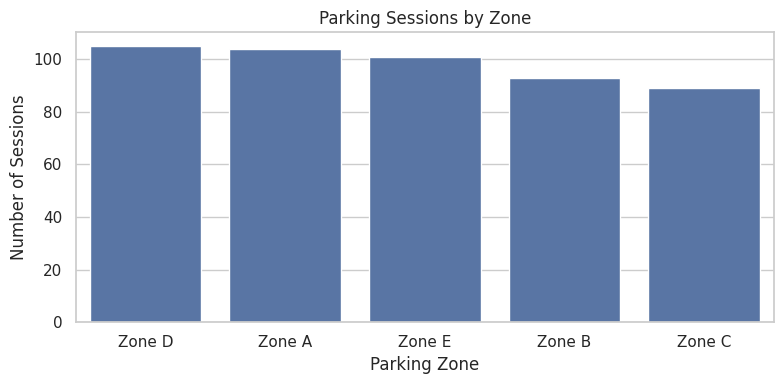


========== HOURLY PARKING DEMAND ==========


,entry_hour,sessions
18,18,36
14,14,35
8,8,34
19,19,34
17,17,32


Peak entry hour: 18:00 (36 sessions)


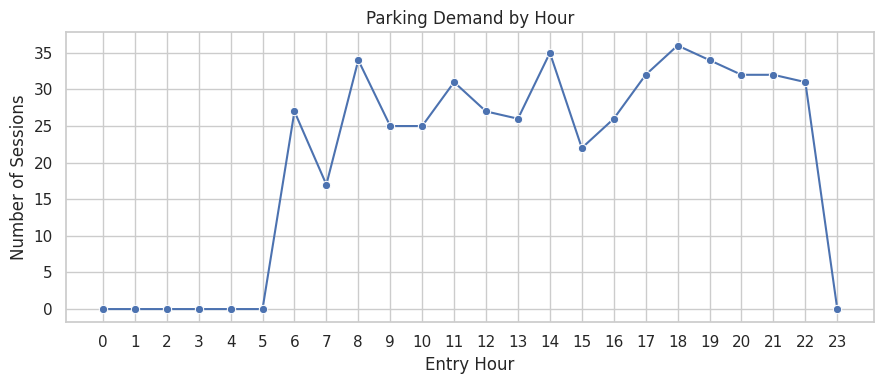


========== PARKING DURATION ==========
Average duration: 2.19 hours
Median duration: 1.9 hours


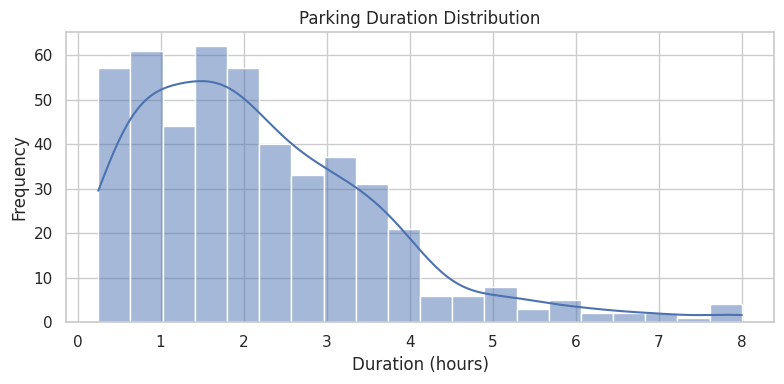


========== DURATION BY ZONE TYPE ==========


,count,mean,median
zone_type,,,
Commercial,195,2.18,1.88
Hospital,104,2.02,1.70
Recreational,97,2.33,2.35
Transit,86,2.24,1.88


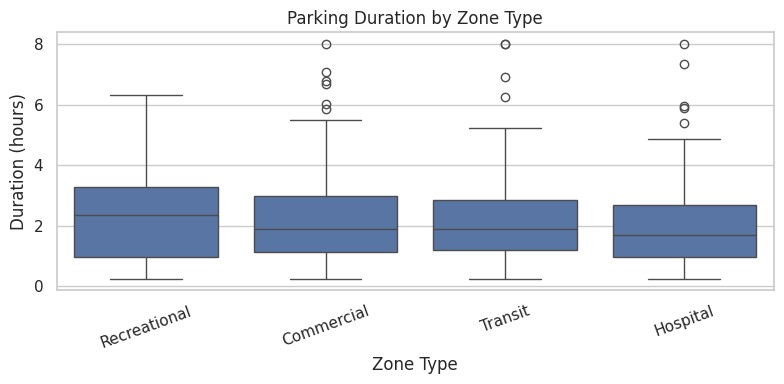


========== EVENT COMPARISON ==========


,count,mean
event,,
Non-event,464,1.0
Event,28,1.0


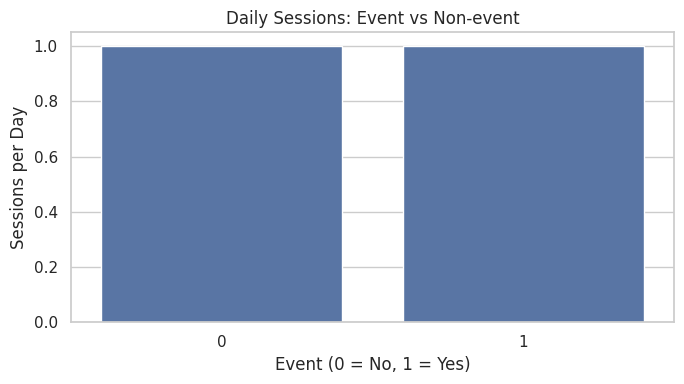


========== WEATHER COMPARISON ==========


,count,mean
rain,,
No Rain,363,1.0
Rain,129,1.0


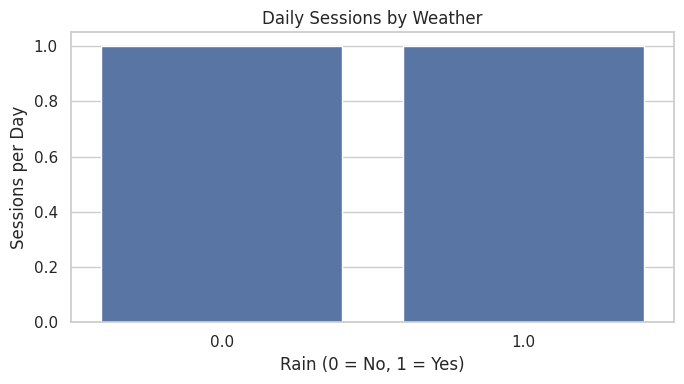


========== KEY EDA FINDINGS ==========
Highest session-count zone: Zone D - 105 sessions
Lowest session-count zone: Zone C - 89 sessions
Busiest entry hour: 18:00
Average valid parking duration: 2.19 hours

STEP 4 COMPLETED!


In [10]:

# ============================================================
# ROUND 2 - STEP 4: EXPLORATORY DATA ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

# 1. DESCRIPTIVE STATISTICS
print("========== DESCRIPTIVE STATISTICS ==========")
display(
    data[["duration", "fee", "entry_hour", "temperature"]]
    .describe()
)

# 2. PARKING SESSIONS BY ZONE
zone_counts = (
    data.groupby("zone")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="sessions")
)

print("\n========== PARKING SESSIONS BY ZONE ==========")
display(zone_counts)

plt.figure(figsize=(8, 4))
sns.barplot(data=zone_counts, x="zone", y="sessions")
plt.title("Parking Sessions by Zone")
plt.xlabel("Parking Zone")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

# 3. PEAK PARKING HOURS
hourly = (
    data.groupby("entry_hour")
    .size()
    .reindex(range(24), fill_value=0)
    .rename("sessions")
    .reset_index()
)

print("\n========== HOURLY PARKING DEMAND ==========")
display(hourly.sort_values("sessions", ascending=False).head(5))

peak_row = hourly.loc[hourly["sessions"].idxmax()]
print(
    f"Peak entry hour: {int(peak_row['entry_hour']):02d}:00 "
    f"({int(peak_row['sessions'])} sessions)"
)

plt.figure(figsize=(9, 4))
sns.lineplot(data=hourly, x="entry_hour", y="sessions", marker="o")
plt.title("Parking Demand by Hour")
plt.xlabel("Entry Hour")
plt.ylabel("Number of Sessions")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

# 4. PARKING DURATION DISTRIBUTION
print("\n========== PARKING DURATION ==========")
print("Average duration:", round(data["duration"].mean(), 2), "hours")
print("Median duration:", round(data["duration"].median(), 2), "hours")

plt.figure(figsize=(8, 4))
sns.histplot(data=data, x="duration", bins=20, kde=True)
plt.title("Parking Duration Distribution")
plt.xlabel("Duration (hours)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 5. DURATION BY ZONE TYPE
duration_by_type = (
    data.groupby("zone_type", observed=True)["duration"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("\n========== DURATION BY ZONE TYPE ==========")
display(duration_by_type)

plt.figure(figsize=(8, 4))
sns.boxplot(data=data, x="zone_type", y="duration")
plt.title("Parking Duration by Zone Type")
plt.xlabel("Zone Type")
plt.ylabel("Duration (hours)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 6. EVENT VS NON-EVENT COMPARISON
event_daily = (
    data.dropna(subset=["event"])
    .groupby(["date", "event"])
    .size()
    .reset_index(name="sessions")
)

event_summary = (
    event_daily.groupby("event")["sessions"]
    .agg(["count", "mean"])
    .round(2)
)

event_summary.index = event_summary.index.map(
    {0: "Non-event", 1: "Event"}
)

print("\n========== EVENT COMPARISON ==========")
display(event_summary)

plt.figure(figsize=(7, 4))
sns.barplot(data=event_daily, x="event", y="sessions")
plt.title("Daily Sessions: Event vs Non-event")
plt.xlabel("Event (0 = No, 1 = Yes)")
plt.ylabel("Sessions per Day")
plt.tight_layout()
plt.show()

# 7. RAIN VS NO-RAIN COMPARISON
weather_daily = (
    data.dropna(subset=["rain"])
    .groupby(["date", "rain"])
    .size()
    .reset_index(name="sessions")
)

weather_summary = (
    weather_daily.groupby("rain")["sessions"]
    .agg(["count", "mean"])
    .round(2)
)

weather_summary.index = weather_summary.index.map(
    {0: "No Rain", 1: "Rain"}
)

print("\n========== WEATHER COMPARISON ==========")
display(weather_summary)

plt.figure(figsize=(7, 4))
sns.barplot(data=weather_daily, x="rain", y="sessions")
plt.title("Daily Sessions by Weather")
plt.xlabel("Rain (0 = No, 1 = Yes)")
plt.ylabel("Sessions per Day")
plt.tight_layout()
plt.show()

# 8. FINAL EDA FINDINGS
print("\n========== KEY EDA FINDINGS ==========")

print(
    "Highest session-count zone:",
    zone_counts.iloc[0]["zone"],
    "-",
    int(zone_counts.iloc[0]["sessions"]),
    "sessions"
)

print(
    "Lowest session-count zone:",
    zone_counts.iloc[-1]["zone"],
    "-",
    int(zone_counts.iloc[-1]["sessions"]),
    "sessions"
)

print(
    "Busiest entry hour:",
    f"{int(peak_row['entry_hour']):02d}:00"
)

print(
    "Average valid parking duration:",
    round(data["duration"].mean(), 2),
    "hours"
)

print("\nSTEP 4 COMPLETED!")


ZONE-WISE UTILIZATION INDICATORS


,zone,total_sessions,avg_duration_hours,total_fee,capacity,sessions_per_capacity
3,Zone D,105,2.02,3586.64,50.0,2.10
1,Zone B,93,2.08,3188.62,60.0,1.55
4,Zone E,101,2.33,3840.46,70.0,1.44
0,Zone A,104,2.28,3726.91,80.0,1.30
2,Zone C,89,2.24,3290.20,100.0,0.89


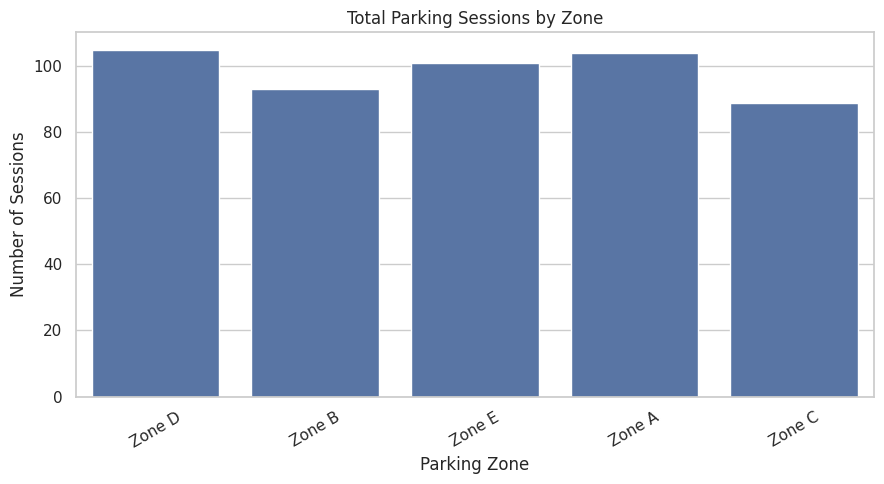

SESSIONS BY TIME PERIOD


,time_period,total_sessions
1,Morning,159
2,Afternoon,136
3,Evening,134
4,Late Night,63
0,Night,0


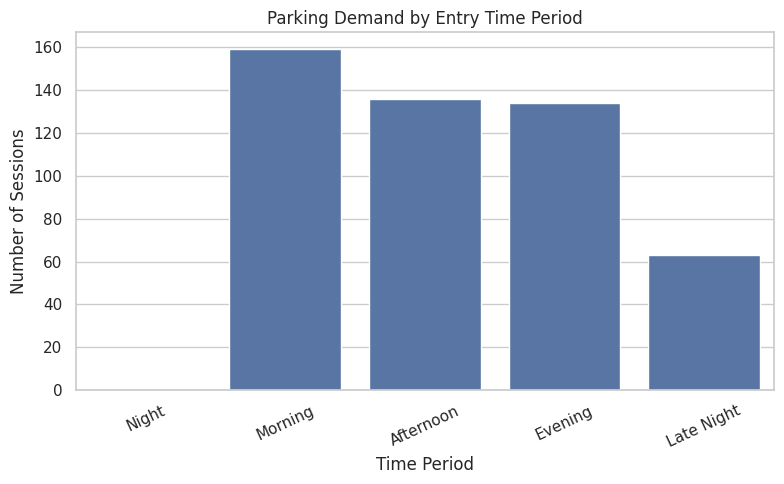

LOWEST TO HIGHEST TURNOVER PROXY


,zone,total_sessions,capacity,avg_duration_hours,sessions_per_space
2,Zone C,89,100.0,2.24,0.89
0,Zone A,104,80.0,2.28,1.30
4,Zone E,101,70.0,2.33,1.44
1,Zone B,93,60.0,2.08,1.55
3,Zone D,105,50.0,2.02,2.10


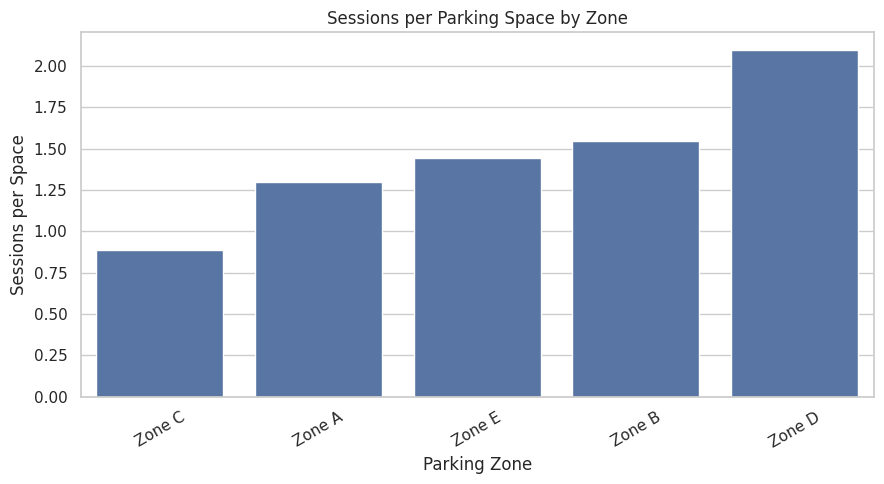


KEY FINDINGS
Highest sessions-per-capacity indicator: Zone D (2.10)
Lowest sessions-per-capacity indicator: Zone C (0.89)
Busiest entry period: Morning (159 sessions)

Important: These are session-based indicators. True occupancy requires entry and exit timestamps to calculate how many vehicles were parked simultaneously.


In [11]:

# CELL 5: OCCUPANCY, PEAK PERIODS AND TURNOVER

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Zone-wise session count
zone_sessions = (
    data.groupby("zone")
    .agg(
        total_sessions=("session_id", "nunique"),
        avg_duration_hours=("duration", "mean"),
        total_fee=("fee", "sum")
    )
    .reset_index()
)

# 2. Calculate zone utilization using available capacity
# Note: This is an approximate utilization indicator,
# not true concurrent occupancy.

zone_sessions = zone_sessions.merge(
    zones_unique[["zone", "capacity"]],
    on="zone",
    how="left"
)

zone_sessions["sessions_per_capacity"] = (
    zone_sessions["total_sessions"] /
    zone_sessions["capacity"].replace(0, np.nan)
)

zone_sessions = zone_sessions.sort_values(
    "sessions_per_capacity", ascending=False
)

print("ZONE-WISE UTILIZATION INDICATORS")
display(zone_sessions.round(2))

# Plot zone-wise sessions
plt.figure(figsize=(9, 5))
sns.barplot(
    data=zone_sessions,
    x="zone",
    y="total_sessions"
)
plt.title("Total Parking Sessions by Zone")
plt.xlabel("Parking Zone")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 3. Peak entry periods
peak_periods = (
    data.groupby("time_period", observed=False)
    .agg(total_sessions=("session_id", "nunique"))
    .reset_index()
    .sort_values("total_sessions", ascending=False)
)

print("SESSIONS BY TIME PERIOD")
display(peak_periods)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=peak_periods,
    x="time_period",
    y="total_sessions"
)
plt.title("Parking Demand by Entry Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


# 4. Vehicle turnover indicator
# Turnover proxy = sessions per parking space over the observation period.
# This is not a daily turnover rate.

turnover = zone_sessions[
    ["zone", "total_sessions", "capacity", "avg_duration_hours"]
].copy()

turnover["sessions_per_space"] = (
    turnover["total_sessions"] /
    turnover["capacity"].replace(0, np.nan)
)

turnover = turnover.sort_values(
    "sessions_per_space", ascending=True
)

print("LOWEST TO HIGHEST TURNOVER PROXY")
display(turnover.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=turnover,
    x="zone",
    y="sessions_per_space"
)
plt.title("Sessions per Parking Space by Zone")
plt.xlabel("Parking Zone")
plt.ylabel("Sessions per Space")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 5. Key findings
print("\nKEY FINDINGS")

if not zone_sessions.empty:
    highest = zone_sessions.iloc[0]
    lowest = zone_sessions.iloc[-1]

    print(
        f"Highest sessions-per-capacity indicator: "
        f"{highest['zone']} ({highest['sessions_per_capacity']:.2f})"
    )
    print(
        f"Lowest sessions-per-capacity indicator: "
        f"{lowest['zone']} ({lowest['sessions_per_capacity']:.2f})"
    )

if not peak_periods.empty:
    peak = peak_periods.iloc[0]
    print(
        f"Busiest entry period: {peak['time_period']} "
        f"({peak['total_sessions']} sessions)"
    )

print(
    "\nImportant: These are session-based indicators. "
    "True occupancy requires entry and exit timestamps "
    "to calculate how many vehicles were parked simultaneously."
)


EVENT DAY COMPARISON


,event_category,total_sessions,avg_duration_hours,avg_fee
0,Event day,28,2.37,37.74
1,Non-event day,464,2.18,35.72


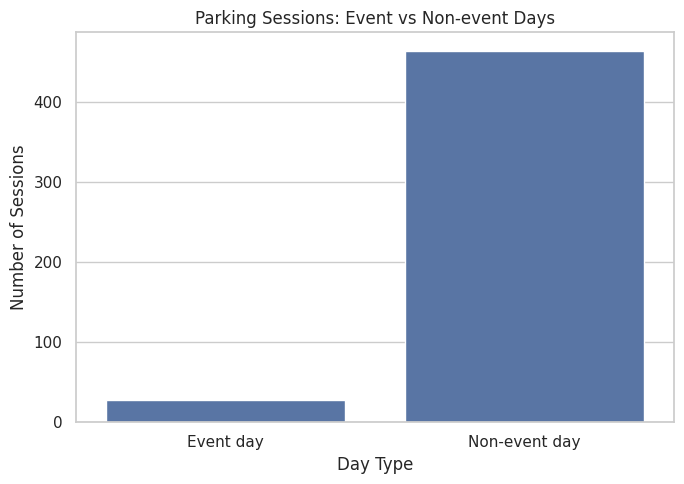

WEATHER COMPARISON


,weather_category,total_sessions,avg_duration_hours,avg_fee
0,No rain,363,2.24,36.63
1,Rain,129,2.04,33.61


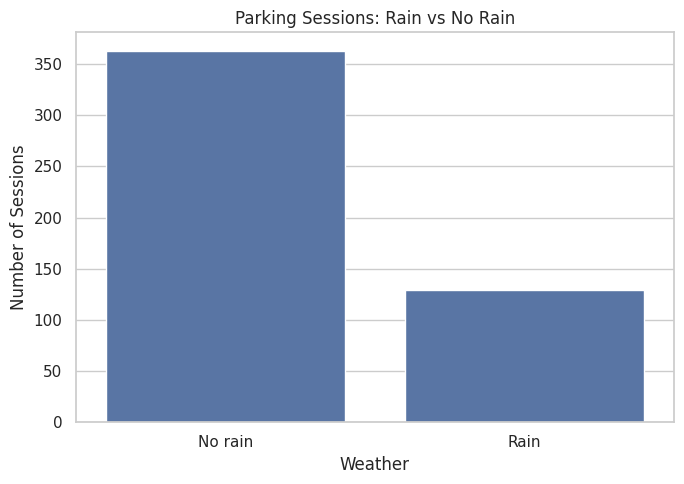

DURATION BY EVENT AND WEATHER


,event,rain,sessions,avg_duration_hours
0,0,0.0,342,2.25
1,0,1.0,122,1.98
2,1,0.0,21,2.13
3,1,1.0,7,3.09


Correlation between temperature and parking duration: -0.009


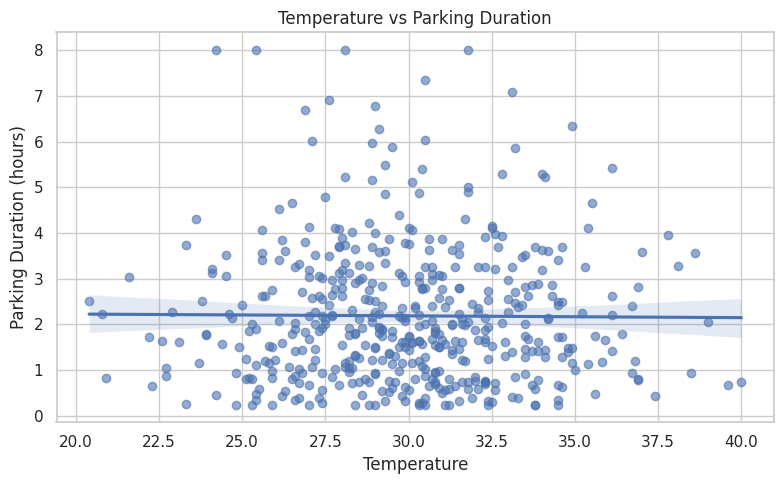


INTERPRETATION
Compare the average duration and session counts across groups.
A difference indicates an association, not necessarily causation.
Because the sample contains approximately one session per date, session counts alone cannot reliably measure daily parking demand.


In [12]:

# CELL 6: EVENT AND WEATHER IMPACT ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Compare event days and non-event days
event_data = data.dropna(subset=["is_event_day"]).copy()

event_data["event_category"] = event_data["is_event_day"].map({
    0: "Non-event day",
    1: "Event day"
})

event_summary = (
    event_data.groupby("event_category", observed=True)
    .agg(
        total_sessions=("session_id", "nunique"),
        avg_duration_hours=("duration", "mean"),
        avg_fee=("fee", "mean")
    )
    .reset_index()
)

print("EVENT DAY COMPARISON")
display(event_summary.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(
    data=event_summary,
    x="event_category",
    y="total_sessions"
)
plt.title("Parking Sessions: Event vs Non-event Days")
plt.xlabel("Day Type")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()


# 2. Compare rainy and non-rainy days
weather_data = data.dropna(subset=["rain"]).copy()

weather_data["weather_category"] = weather_data["rain"].map({
    0: "No rain",
    1: "Rain"
})

weather_summary = (
    weather_data.groupby("weather_category", observed=True)
    .agg(
        total_sessions=("session_id", "nunique"),
        avg_duration_hours=("duration", "mean"),
        avg_fee=("fee", "mean")
    )
    .reset_index()
)

print("WEATHER COMPARISON")
display(weather_summary.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(
    data=weather_summary,
    x="weather_category",
    y="total_sessions"
)
plt.title("Parking Sessions: Rain vs No Rain")
plt.xlabel("Weather")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()


# 3. Compare average parking duration
duration_comparison = (
    data.groupby(
        ["event", "rain"],
        dropna=False,
        observed=True
    )
    .agg(
        sessions=("session_id", "nunique"),
        avg_duration_hours=("duration", "mean")
    )
    .reset_index()
)

print("DURATION BY EVENT AND WEATHER")
display(duration_comparison.round(2))


# 4. Check temperature and duration relationship
temperature_data = data.dropna(
    subset=["temperature", "duration"]
)

if len(temperature_data) >= 2:
    correlation = temperature_data[
        ["temperature", "duration"]
    ].corr().iloc[0, 1]

    print(
        f"Correlation between temperature and parking duration: "
        f"{correlation:.3f}"
    )

    plt.figure(figsize=(8, 5))
    sns.regplot(
        data=temperature_data,
        x="temperature",
        y="duration",
        scatter_kws={"alpha": 0.6}
    )
    plt.title("Temperature vs Parking Duration")
    plt.xlabel("Temperature")
    plt.ylabel("Parking Duration (hours)")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough valid records for temperature correlation.")


# 5. Print a cautious interpretation
print("\nINTERPRETATION")
print("Compare the average duration and session counts across groups.")
print("A difference indicates an association, not necessarily causation.")
print(
    "Because the sample contains approximately one session per date, "
    "session counts alone cannot reliably measure daily parking demand."
)


In [13]:

# CELL 7: FEATURE SELECTION AND FINAL SUMMARY

import pandas as pd
import numpy as np

# 1. Select useful analytical features
candidate_features = [
    "entry_hour",
    "duration",
    "fee",
    "capacity",
    "temperature",
    "rain",
    "is_event_day",
    "is_weekend",
    "zone",
    "zone_type",
    "time_period"
]

# Keep only columns available in the merged dataset
selected_features = [
    col for col in candidate_features if col in data.columns
]

feature_data = data[selected_features].copy()

print("SELECTED FEATURES")
print(selected_features)

print("\nFEATURE DATASET SHAPE")
print(feature_data.shape)

print("\nFEATURE DATASET PREVIEW")
display(feature_data.head())


# 2. Identify missing values in analytical features
missing_summary = (
    feature_data.isna()
    .sum()
    .reset_index()
)

missing_summary.columns = ["feature", "missing_values"]
missing_summary["missing_percentage"] = (
    missing_summary["missing_values"] /
    len(feature_data) * 100
).round(2)

print("\nMISSING VALUES IN SELECTED FEATURES")
display(missing_summary)


# 3. Descriptive summary for numerical features
numeric_features = feature_data.select_dtypes(
    include=np.number
)

print("\nNUMERICAL FEATURE SUMMARY")
display(numeric_features.describe().round(2))


# 4. Correlation analysis for numerical features
if numeric_features.shape[1] >= 2:
    correlation_matrix = numeric_features.corr()

    print("\nCORRELATION MATRIX")
    display(correlation_matrix.round(2))
else:
    print("Not enough numerical features for correlation analysis.")


# 5. Overall business summary
print("\n" + "=" * 50)
print("PARKING UTILIZATION INSIGHT - SUMMARY")
print("=" * 50)

print(f"Number of cleaned session records: {len(data)}")
print(f"Number of zones represented: {data['zone'].nunique()}")

if "duration" in data.columns:
    print(
        "Average parking duration:",
        round(data["duration"].mean(), 2),
        "hours"
    )

if "fee" in data.columns:
    print(
        "Total recorded parking fees:",
        round(data["fee"].sum(), 2)
    )

if "entry_hour" in data.columns and data["entry_hour"].notna().any():
    busiest_hour = data["entry_hour"].value_counts().idxmax()
    print(f"Busiest recorded entry hour: {int(busiest_hour):02d}:00")

print("\nInterpret results cautiously:")
print("- Session counts describe recorded parking activity.")
print("- Sessions per capacity is a comparative indicator.")
print("- True occupancy needs simultaneous entry/exit analysis.")
print("- Event and weather relationships are not proof of causation.")


SELECTED FEATURES
['entry_hour', 'duration', 'fee', 'capacity', 'temperature', 'rain', 'is_event_day', 'is_weekend', 'zone', 'zone_type', 'time_period']

FEATURE DATASET SHAPE
(492, 11)

FEATURE DATASET PREVIEW


,entry_hour,duration,fee,capacity,temperature,rain,is_event_day,is_weekend,zone,zone_type,time_period
0,13,3.850000,49.80,70.0,26.2,0.0,0,0,Zone E,Recreational,Afternoon
1,7,0.616667,10.00,60.0,30.9,0.0,0,0,Zone B,Commercial,Morning
2,17,1.716667,30.76,100.0,30.0,0.0,0,0,Zone C,Transit,Evening
3,20,1.016667,28.31,50.0,26.7,0.0,0,1,Zone D,Hospital,Evening
4,20,1.550000,21.41,60.0,28.0,0.0,1,1,Zone B,Commercial,Evening



MISSING VALUES IN SELECTED FEATURES


,feature,missing_values,missing_percentage
0,entry_hour,0,0.00
1,duration,10,2.03
2,fee,0,0.00
3,capacity,0,0.00
4,temperature,0,0.00
5,rain,0,0.00
6,is_event_day,0,0.00
7,is_weekend,0,0.00
8,zone,0,0.00
9,zone_type,0,0.00



NUMERICAL FEATURE SUMMARY


,entry_hour,duration,fee,capacity,temperature,rain,is_event_day,is_weekend
count,492.00,482.00,492.00,492.00,492.00,492.00,492.0,492.00
mean,14.43,2.19,35.84,71.38,29.97,0.26,0.06,0.29
std,4.88,1.49,22.53,16.94,3.37,0.44,0.23,0.45
min,6.00,0.25,10.00,50.00,20.40,0.00,0.0,0.00
25%,10.00,1.05,19.16,60.00,27.70,0.00,0.0,0.00
50%,14.00,1.90,31.24,70.00,29.95,0.00,0.0,0.00
75%,19.00,3.03,47.86,80.00,32.30,1.00,0.0,1.00
max,22.00,8.00,135.61,100.00,40.00,1.00,1.0,1.00



CORRELATION MATRIX


,entry_hour,duration,fee,capacity,temperature,rain,is_event_day,is_weekend
entry_hour,1.00,-0.09,-0.09,0.00,-0.01,0.09,-0.02,0.07
duration,-0.09,1.00,0.97,0.06,-0.01,-0.06,0.03,-0.07
fee,-0.09,0.97,1.00,0.04,-0.02,-0.06,0.02,-0.08
capacity,0.00,0.06,0.04,1.00,-0.01,-0.04,-0.06,0.00
temperature,-0.01,-0.01,-0.02,-0.01,1.00,0.01,0.03,-0.11
rain,0.09,-0.06,-0.06,-0.04,0.01,1.00,-0.01,0.02
is_event_day,-0.02,0.03,0.02,-0.06,0.03,-0.01,1.00,0.23
is_weekend,0.07,-0.07,-0.08,0.00,-0.11,0.02,0.23,1.00



PARKING UTILIZATION INSIGHT - SUMMARY
Number of cleaned session records: 492
Number of zones represented: 5
Average parking duration: 2.19 hours
Total recorded parking fees: 17632.83
Busiest recorded entry hour: 18:00

Interpret results cautiously:
- Session counts describe recorded parking activity.
- Sessions per capacity is a comparative indicator.
- True occupancy needs simultaneous entry/exit analysis.
- Event and weather relationships are not proof of causation.


In [14]:

# CELL 8: EXPORT DATA FOR EXCEL ANALYSIS

import os

OUTPUT_DIR = "/content/parking_analysis_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Export the cleaned merged dataset
data.to_csv(
    os.path.join(OUTPUT_DIR, "cleaned_parking_analysis.csv"),
    index=False
)

# Export useful summary tables
zone_summary = (
    data.groupby("zone")
    .agg(
        total_sessions=("session_id", "nunique"),
        average_duration=("duration", "mean"),
        total_fees=("fee", "sum"),
        average_fee=("fee", "mean")
    )
    .reset_index()
)

hourly_summary = (
    data.groupby("entry_hour")
    .agg(total_sessions=("session_id", "nunique"))
    .reset_index()
    .sort_values("entry_hour")
)

duration_summary = (
    data.groupby("zone_type", dropna=False, observed=True)
    .agg(
        session_count=("session_id", "nunique"),
        average_duration=("duration", "mean"),
        median_duration=("duration", "median")
    )
    .reset_index()
)

event_summary_export = (
    data.groupby("is_event_day", dropna=False)
    .agg(
        session_count=("session_id", "nunique"),
        average_duration=("duration", "mean")
    )
    .reset_index()
)

weather_summary_export = (
    data.groupby("rain", dropna=False)
    .agg(
        session_count=("session_id", "nunique"),
        average_duration=("duration", "mean")
    )
    .reset_index()
)

# Write multiple analysis sheets to one Excel workbook
excel_path = os.path.join(
    OUTPUT_DIR,
    "Parking_Utilization_Analysis.xlsx"
)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    data.to_excel(writer, sheet_name="Cleaned_Data", index=False)
    zone_summary.to_excel(writer, sheet_name="Zone_Summary", index=False)
    hourly_summary.to_excel(writer, sheet_name="Hourly_Summary", index=False)
    duration_summary.to_excel(writer, sheet_name="Duration_by_Zone_Type", index=False)
    event_summary_export.to_excel(writer, sheet_name="Event_Analysis", index=False)
    weather_summary_export.to_excel(writer, sheet_name="Weather_Analysis", index=False)
    missing_summary.to_excel(writer, sheet_name="Missing_Values", index=False)

print("EXPORT COMPLETED SUCCESSFULLY!")
print("\nFiles created:")
print(os.path.join(OUTPUT_DIR, "cleaned_parking_analysis.csv"))
print(excel_path)

print("\nExcel workbook sheets:")
print(
    "Cleaned_Data, Zone_Summary, Hourly_Summary, "
    "Duration_by_Zone_Type, Event_Analysis, "
    "Weather_Analysis, Missing_Values"
)


EXPORT COMPLETED SUCCESSFULLY!

Files created:
/content/parking_analysis_output/cleaned_parking_analysis.csv
/content/parking_analysis_output/Parking_Utilization_Analysis.xlsx

Excel workbook sheets:
Cleaned_Data, Zone_Summary, Hourly_Summary, Duration_by_Zone_Type, Event_Analysis, Weather_Analysis, Missing_Values


In [15]:

from google.colab import files

files.download(
    "/content/parking_analysis_output/Parking_Utilization_Analysis.xlsx"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>